# 08 — Monthly major incidents per line: what a time-series model has to work with

**Goal.** Before forecasting next month's major incidents on each line (and asking
whether a VAR helps), look at the monthly counts. A VAR predicts each line from the
recent past of every line, so it needs two things: memory over time, and lines that
move together with a delay. This notebook checks both, plus the size of the counts
and any seasonality.

Training years only (2019-2023), so nothing here looks at the holdout. A multi-line
incident counts on each line it involves.

Questions:
1. How large and how variable are the monthly counts?
2. Is there a seasonal pattern?
3. Does a line's count carry over to the next month, on the same line or on others?

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

# The notebook lives in code/exploration/; the project modules live in code/.
sys.path.insert(0, str(Path.cwd().parent))
from cleaning.load import load_incidents
from modeling.forecast import monthly_major_counts
from modeling.target import add_targets, model_population

## 1. Size and spread of the counts

In [2]:
labelled = add_targets(model_population(load_incidents()))
counts = monthly_major_counts(labelled).loc[:"2023-12"]

pd.DataFrame({
    "mean per month": counts.mean(),
    "variance / mean": counts.var() / counts.mean(),
    "months with 0": (counts == 0).mean(),
}).round(2)

,mean per month,variance / mean,months with 0
line,,,
blue,3.20,1.27,0.08
green,9.30,1.21,0.00
orange,7.17,1.78,0.00
yellow,1.08,0.89,0.33


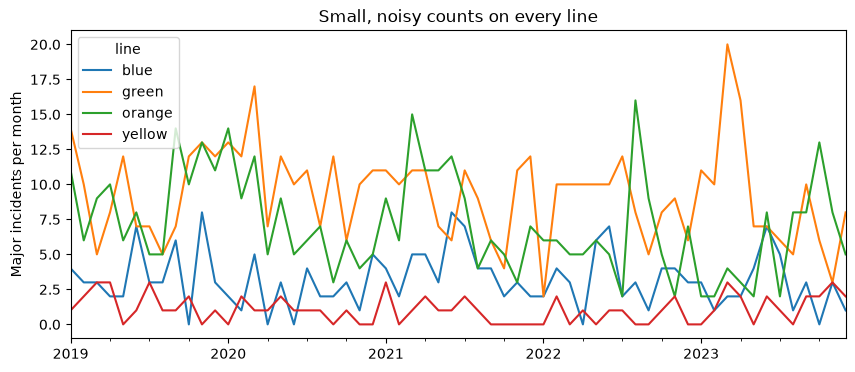

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
counts.plot(ax=ax, linewidth=1.5)
ax.set_ylabel("Major incidents per month")
ax.set_xlabel("")
ax.set_title("Small, noisy counts on every line")
plt.show()

**Reading.** The counts are small: about 1 a month on yellow, 3 on blue, 7 on
orange, 9 on green. The variance is close to the mean (ratio 0.9 to 1.8), which is what
pure chance gives for counts (a Poisson process has a ratio of 1). Most of the month to
month movement is therefore noise that no model can forecast.

## 2. Seasonality

In [4]:
long = counts.stack().rename("count").reset_index()
long["calendar_month"] = long["month"].dt.month

lines_only = smf.glm("count ~ line", long, family=sm.families.Poisson()).fit()
with_month = smf.glm("count ~ line + C(calendar_month)", long, family=sm.families.Poisson()).fit()
lr = lines_only.deviance - with_month.deviance
print(f"Likelihood ratio {lr:.1f} on 11 df, p = {stats.chi2.sf(lr, 11):.2f}")

counts.groupby(counts.index.month).mean().round(1).T

Likelihood ratio 14.1 on 11 df, p = 0.23


month,1,2,3,4,5,6,7,8,9,10,11,12
line,,,,,,,,,,,,
blue,3.0,2.2,3.6,1.8,3.6,5.8,4.2,2.6,3.2,1.8,3.8,2.8
green,10.2,10.4,12.6,10.4,9.6,8.0,9.4,6.8,8.0,7.2,9.2,9.8
orange,8.4,5.8,9.0,6.8,6.8,7.6,4.8,8.0,8.0,7.8,6.0,7.0
yellow,0.8,1.4,1.6,1.8,0.6,1.2,1.6,0.6,0.6,1.2,1.0,0.6


**Reading.** Adding the calendar month to a Poisson model with a level per line does
not improve the fit beyond chance (p about 0.23). The month-of-year averages move
around, but not in a way that repeats reliably. A seasonal forecast should not beat a
flat one.

## 3. Memory: same line and across lines

In [5]:
# Row = line this month, column = line last month: correlation of the two counts.
lagged = pd.DataFrame({
    last: {now: counts[now].corr(counts[last].shift(1)) for now in counts.columns}
    for last in counts.columns
})
lagged.round(2)

,blue,green,orange,yellow
blue,-0.04,-0.09,-0.07,-0.13
green,-0.14,0.23,0.00,0.00
orange,-0.09,0.03,0.31,-0.01
yellow,0.11,-0.11,0.18,0.10


**Reading.** The diagonal is the memory of each line: about 0.2 to 0.3 on green and
orange, near zero on blue and yellow. Off the diagonal (one line's last month against
another line's this month) every correlation is between -0.15 and 0.2, with no
pattern, which is what noise gives with 60 months. The cross-line terms are the only
thing a VAR adds over a separate model per line, and here they have nothing to pick
up. With 4 lines, a VAR(1) fits 4 extra numbers per line from that noise.

## Conclusion

* Forecasters to compare (`code/modeling/forecast.py`): the line's long-run mean,
  its last-12-month mean, the same month last year, a Poisson regression on line +
  calendar month, an AR(1) per line, and a VAR(1).
* Expectations from this notebook: the seasonal forecasts should not help, the
  AR(1) may help a little on green and orange, and the VAR should not beat the AR(1).